# Scaffold analysis and Hammett feasibility screen

Takes the two datasets, previously bult in notebook 01, to check if either contains congeneric series of compounds, suitable for Hammett analysis. This means we are looking for compounds that share the same core and there are substituents varying at the single aromatic position. Substituents should vary between both electron-donating and electron-withdrawing substituents.

#### Method

* Murcko scaffold binning (`includeChirality=False`), then R-group (substituents in the target position) decomposition on the largest bins.
* Congeneric series is found by leave-one-position-out: for each R position, group compounds by all other positions and keep groups where the target position varies.
* Ring position was assigned by drawing each core with atom indices and counting from the scaffold attachment.


#### Pre-registered gate

At least 6 compounds as floor, varying at the single aromatic position and having σ interval of 0.8 between both donors and acceptors.

#### Inputs
* `nav_set.csv`, `ser_set.csv` from `data/processed/`
* `constant_values.csv` from `data/raw/` — tabulated σ_m and σ_p constants, manually transcribed from [A Survey of Hammett Substituent Constants and Resonance and Field Parameter](https://pubs.acs.org/chreay/article/91/2/165/181922/A-survey-of-Hammett-substituent-constants-and)

#### Outputs
* `hammett_candidates.csv` to `data/processed/`

Salt stripping is applied to the serotonin set before scaffolding: 52 SMILES carry counterions.


In [1]:
#import section
from IPython.display import SVG
from pathlib import Path

from rdkit import Chem
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem import Draw
from rdkit.Chem.rdRGroupDecomposition import RGroupDecompose
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.info')
import pandas as pd


In [2]:
#setting paths for the notebook

FIGURES = Path('../figures')
PROCESSED = Path('../data/processed')
RAW = Path('../data/raw')
RAW.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)

In [3]:
#dataset import
nav_dataset = pd.read_csv(PROCESSED / 'nav_set.csv')
ser_dataset = pd.read_csv(PROCESSED / 'ser_set.csv')

In [4]:
#nav dataset inspection
nav_dataset.head()

,molecule_chembl_id,pchembl_value_nav11,pchembl_value_nav16,canonical_smiles_nav16
0,CHEMBL4435054,4.52,7.04,CC(C)N(C)Cc1cccc(F)c1CNc1cc(F)c(S(=O)(=O)Nc2cs...
1,CHEMBL4444000,4.52,6.70,O=S(=O)(Nc1cscn1)c1cc(Cl)c(NCc2c(F)cccc2CN2CCC...
2,CHEMBL4445144,5.10,6.14,COc1ccc(F)c([C@H](C)Nc2cc(F)c(S(=O)(=O)Nc3cscn...
3,CHEMBL4448084,4.52,6.29,CC1(C)CCN1Cc1cccc(F)c1CNc1cc(F)c(S(=O)(=O)Nc2c...
4,CHEMBL4450313,5.64,6.22,O=S(=O)(Nc1cscn1)c1cc(Cl)c(NCc2cc(F)ccc2F)cc1F


In [5]:
#serotonin dataset inspection
ser_dataset.head()

,molecule_chembl_id,pchembl_value_5ht1b,pchembl_value_5ht1d,canonical_smiles_5ht1d
0,CHEMBL101686,6.96,7.50,CCCCCCCC(=O)Nc1ccc2[nH]cc(C3CCN(C)CC3)c2n1
1,CHEMBL101690,6.37,6.62,CN1CCC(c2c[nH]c3ccc(NC(=O)c4ccc(F)cc4)cc23)CC1
2,CHEMBL102250,5.96,6.03,CN1CCC(c2c[nH]c3ccc(NC(=O)c4ccoc4)nc23)CC1
3,CHEMBL103424,6.82,6.41,CC(=O)Nc1ccc2[nH]cc(C3CCN(C)CC3)c2c1
4,CHEMBL103479,6.14,5.92,CN1CCC(c2c[nH]c3ccc(NC(=O)c4ccc(F)cc4)nc23)CC1


In [6]:
#checking if the smiles molecules representations have any ions, for nav dataset
nav_dataset['canonical_smiles_nav16'].str.contains('.', regex=False).value_counts()

canonical_smiles_nav16
False    711
Name: count, dtype: int64

In [7]:
#checking if the smiles molecules representations have any ions, for serotonin dataset
ser_dataset['canonical_smiles_5ht1d'].str.contains('.', regex=False).value_counts()

canonical_smiles_5ht1d
False    649
True      52
Name: count, dtype: int64

In [8]:
#creating molecule objects inside datasets
nav_mols = nav_dataset['canonical_smiles_nav16'].apply(Chem.MolFromSmiles)
ser_mols = ser_dataset['canonical_smiles_5ht1d'].apply(Chem.MolFromSmiles)


In [9]:
#cleaning failed molecule objects
nav_mols = [mol for mol in nav_mols if mol]
ser_mols = [mol for mol in ser_mols if mol]

print(f"nav: {len(nav_mols)} of {len(nav_dataset)} parsed")
print(f"ser: {len(ser_mols)} of {len(ser_dataset)} parsed")

nav: 711 of 711 parsed
ser: 701 of 701 parsed


In [10]:
#since serotonin sets have salt molecules, we have to remove smaller ions from the main molecule
chooser = rdMolStandardize.LargestFragmentChooser()

ser_cleaned = []

for mol in ser_mols:
    new_mol = chooser.choose(mol)
    ser_cleaned.append(new_mol)

len(ser_cleaned)

701

In [11]:
#finding biggest scaffold molecule inside nav dataset

nav_scaffold = []

for mol in nav_mols:

    #Murcko return a Mol
    #value_counts() on Mol objects makes every compound look unique
    #The smiles string will is a the grouping key
    smiles = Chem.MolToSmiles(mol)
    scaffold = MurckoScaffold.MurckoScaffoldSmiles(smiles, includeChirality=False)
    nav_scaffold.append(scaffold)

nav_dataset['scaffold_column'] = nav_scaffold

nav_dataset['scaffold_column'].value_counts()[0:10]

scaffold_column
O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1     84
O=S(=O)(Nc1nccs1)c1ccc(NCc2ccccc2)cc1              51
O=S(=O)(Nc1cscn1)c1ccc(NCc2ccccc2CN2CCC2)cc1       50
O=S(=O)(Nc1cscn1)c1ccc(NCc2ccccc2)cc1              48
O=S(=O)(Nc1nccs1)c1ccc(OC2CCN(Cc3ccccc3)CC2)cc1    35
O=S(=O)(Nc1nccs1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1     18
O=S(=O)(Nc1cscn1)c1ccc(NCc2ccccc2)cn1              13
O=S(=O)(Nc1ncns1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1     12
O=S(=O)(Nc1nccs1)c1ccc(OCc2ccccc2)cc1              12
O=S(=O)(Nc1cscn1)c1ccc(OC2CCN(Cc3ccccc3)CC2)cc1    12
Name: count, dtype: int64

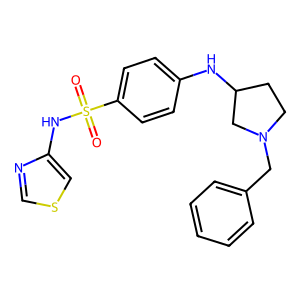

In [12]:
#drawing nav scaffold for biggest scaffold [O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1]
 
nav_scaff_target = nav_dataset['scaffold_column'].value_counts().index[0]

nav_scaff_target_mol = Chem.MolFromSmiles(nav_scaff_target)

Draw.MolToImage(nav_scaff_target_mol)


In [13]:
#Drawing molecules that share the biggest scaffold 

nav_scaff_target_df = nav_dataset[nav_dataset['scaffold_column'] == nav_scaff_target].copy()
nav_scaff_target_df['molecule_objects'] = nav_scaff_target_df['canonical_smiles_nav16'].apply(Chem.MolFromSmiles)

matched = []


for mol in nav_scaff_target_df['molecule_objects']:
    matched.append(mol.GetSubstructMatch(nav_scaff_target_mol))

names = list(nav_scaff_target_df['molecule_chembl_id'])
mols = list(nav_scaff_target_df['molecule_objects'])

splits = range(0,84,8)

for i,j in enumerate(splits):

    if j != 84:
        img = Draw.MolsToGridImage(
        mols=mols[j:j+8], 
        subImgSize=(800,800),
        highlightAtomLists=matched[j:j+8],
        legends=names[j:j+8],
        returnPNG=False,
        molsPerRow=4
                      )

        img.save(FIGURES / f'nav_scaff_mols_{i}.png')
    else:
        pass



Since the scaffold compound is quite complex and the positions of substituents vary, it is hard to make a claim just by looking at the pictures if there is enough constant position substituion so that the Hammett calculation can be taken from the same base compound.
There is also substituion in -CH2-phenyl part of the compound which is insulated from other parts of the compound, since there is no conjugated pi bonds connecting it to the ring that also has to be taken out of the analysis.

In [14]:
#finding the subsitituents and their positions

substituents = []

for mol in nav_scaff_target_df['molecule_objects']:
    sub = Chem.ReplaceCore(mol=mol, coreQuery=nav_scaff_target_mol, labelByIndex=True)
    sub = Chem.MolToSmiles(sub)
    substituents.append(sub)

nav_scaff_target_df['substituents'] = substituents

nav_scaff_target_df['substituents'].value_counts()



substituents
[11*]C.[13*]C.[27*]F                         2
[11*]Cl.[27*]F                               2
[10*]F.[13*]C.[18*]CC.[26*]Cl                2
[13*]C.[18*]C.[26*]Cl                        2
[10*]F.[13*]C.[26*]Cl                        2
                                            ..
[10*]F.[13*]C.[21*]F.[24*]F.[26*]C.[27*]F    1
[10*]F.[13*]C.[24*]OC.[26*]C                 1
[10*]F.[13*]C.[24*]F.[26*]Cl                 1
[11*]C.[13*]C.[24*]F.[27*]F                  1
[13*]C.[26*]C(F)(F)F                         1
Name: count, Length: 77, dtype: int64

Results inconclusive from this type of search, it is seen through length of 77 objects inside 84 molecules. Analysis with more details is required.

In [15]:
#RGroupDecompose search for substituents and their positions. 

subs, empty_pair = RGroupDecompose(cores=nav_scaff_target_mol, mols=nav_scaff_target_df['molecule_objects'], asSmiles=True, asRows=False)
print(empty_pair)
subs_df = pd.DataFrame(subs)
subs_df['molecule_chembl_id'] = nav_scaff_target_df['molecule_chembl_id'].tolist()
subs_df

[]


,Core,R1,R10,R11,R12,R13,R2,R3,R4,R5,R6,R7,R8,R9,molecule_chembl_id
0,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@]2([...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],C[*:2],[H][*:3],[H][*:4],[H][*:5],[H][*:6],[H][*:7],[H][*:8],[H][*:9],CHEMBL5424289
1,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],FC(F)[*:2],[H][*:3],[H][*:4],[H][*:5],[H][*:6],[H][*:7],[H][*:8],[H][*:9],CHEMBL5742817
2,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],C[*:2],[H][*:3],[H][*:4],[H][*:5],C[*:6],F[*:7],[H][*:8],[H][*:9],CHEMBL5744409
3,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],[H][*:5],[H][*:6],Cl[*:7],[H][*:8],[H][*:9],CHEMBL5745855
4,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],[H][*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],[H][*:5],[H][*:6],[H][*:7],[H][*:8],[H][*:9],CHEMBL5748381
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],[H][*:11],[H][*:12],F[*:13],C[*:2],[H][*:3],[H][*:4],[H][*:5],[H][*:6],[H][*:7],[H][*:8],[H][*:9],CHEMBL6038080
80,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],C[*:2],[H][*:3],[H][*:4],[H][*:5],[H][*:6],CO[*:7],[H][*:8],[H][*:9],CHEMBL6043860
81,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],[H][*:5],[H][*:6],F[*:7],[H][*:8],[H][*:9],CHEMBL6049360
82,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],C[*:2],[H][*:3],[H][*:4],[H][*:5],[H][*:6],F[*:7],[H][*:8],[H][*:9],CHEMBL6054815


The product is information stored inside dataframe that can now be extracted properly for a detailed analysis.

In [16]:
#custom function to find the longest three base compounds with a single substituent variation on the same position

def find_longest_sub_scaffold(dataframe):

    df = dataframe.copy()
    
    iteration_range = range(len(df))

    if 'Core' in df.columns:
        df.drop(columns=['Core','molecule_chembl_id'], inplace=True)

    df_columns = df.columns

    dict_of_all_comb = {}

    for column in df_columns:

        df_column_list = list(df_columns)
        df_column_list.remove(column)

        for row in iteration_range:
            new_key =[]
            for column_name in df_column_list:
                new_key.append(column_name+'|'+df[column_name][row])

            new_key=','.join(new_key)

            if new_key not in dict_of_all_comb:
                dict_of_all_comb[new_key] = [(column+'|'+df[column][row],row)]
            else:
                dict_of_all_comb[new_key].append((column+'|'+df[column][row],row))

    filtered_dict = {}

    for key, value in dict_of_all_comb.items():

        list_of_s = []

        for sub, _row in value:
            list_of_s.append(sub)
        
        if len(set(list_of_s)) >=2 :
            filtered_dict[key] = value

    longest_key = sorted(filtered_dict, key=lambda k: len(filtered_dict[k]), reverse=True)

    touples = [(longest_key[0], filtered_dict[longest_key[0]]), (longest_key[1], filtered_dict[longest_key[1]]), (longest_key[2], filtered_dict[longest_key[2]])]

    return touples

nav_longest_scafs_1=find_longest_sub_scaffold(subs_df)

nav_longest_scafs_1

[('R1|[H][*:1],R10|[H][*:10],R11|C[*:11],R12|[H][*:12],R13|F[*:13],R2|Cl[*:2],R3|[H][*:3],R4|[H][*:4],R5|[H][*:5],R7|[H][*:7],R8|[H][*:8],R9|[H][*:9]',
  [('R6|FC(F)(F)[*:6]', 9),
   ('R6|FC(F)[*:6]', 12),
   ('R6|CC(C)(O)[*:6]', 18),
   ('R6|COC(=O)[*:6]', 26),
   ('R6|[H][*:6]', 30),
   ('R6|CC(C)O[*:6]', 34),
   ('R6|FC(F)O[*:6]', 42),
   ('R6|CO[*:6]', 49),
   ('R6|Cl[*:6]', 54),
   ('R6|F[*:6]', 68),
   ('R6|[H][*:6]', 69)]),
 ('R1|[H][*:1],R10|[H][*:10],R11|C[*:11],R12|[H][*:12],R13|F[*:13],R2|Cl[*:2],R3|[H][*:3],R4|[H][*:4],R6|[H][*:6],R7|[H][*:7],R8|[H][*:8],R9|[H][*:9]',
  [('R5|CN(C)[*:5]', 24),
   ('R5|[H][*:5]', 30),
   ('R5|Br[*:5]', 35),
   ('R5|C[*:5]', 37),
   ('R5|CCC[*:5]', 57),
   ('R5|Cl[*:5]', 64),
   ('R5|[H][*:5]', 69),
   ('R5|F[*:5]', 74)]),
 ('R1|[H][*:1],R10|[H][*:10],R11|C[*:11],R12|[H][*:12],R13|F[*:13],R3|[H][*:3],R4|[H][*:4],R5|[H][*:5],R6|[H][*:6],R7|[H][*:7],R8|[H][*:8],R9|[H][*:9]',
  [('R2|C[*:2]', 0),
   ('R2|FC(F)[*:2]', 1),
   ('R2|C[*:2]', 17),
  

In [17]:
#smiles core

subs_df['Core'][1]

'O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2([*:10])CC([*:9])N(C(c3c([*:4])cc([*:5])c([*:6])c3[*:7])[*:8])C2[*:3])[*:11])c([*:12])c1[*:13]'

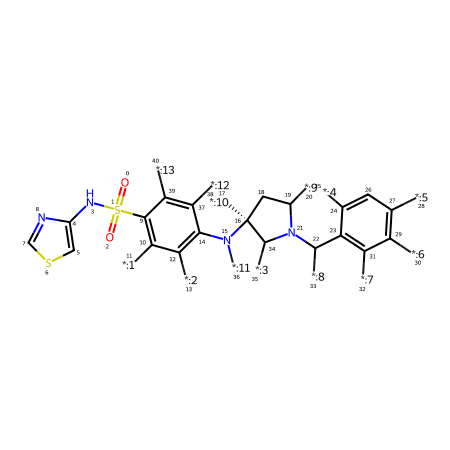

In [18]:
#drawing core 'O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2([*:10])CC([*:9])N(C(c3c([*:4])cc([*:5])c([*:6])c3[*:7])[*:8])C2[*:3])[*:11])c([*:12])c1[*:13]'

drawer=Draw.MolDraw2DSVG(450,450)
opts=drawer.drawOptions()
opts.addAtomIndices=True 

core_1 = subs_df['Core'][1]
core_1 = Chem.MolFromSmiles(core_1)

drawer.DrawMolecule(core_1)
drawer.FinishDrawing()
img=drawer.GetDrawingText()

SVG(img)

In [19]:
#importing values for sigma constants
values = pd.read_csv(RAW / 'constant_values.csv')
values.head()

,entry,substituent_smiles,formula,substituent_name,sigma_m,sigma_p,F,R,ref
0,70.0,FC(F)(F),CF3,trifluoromethyl,0.43,0.54,0.38,0.16,183
1,103.0,FC(F),CHF2,difluoromethyl,0.29,0.32,0.29,0.03,110
2,203.0,COC(=O),COOCH3,methoxycarbonyl group,0.37,0.45,0.34,0.11,175
3,43.0,[H],H,hydrogen,0.00,0.00,0.03,0.00,no quotation
4,142.0,CO,OCH3,methoxy group,0.12,-0.27,0.29,-0.56,183


In [20]:
#Getting values for the first scaffold group for core 'O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2([*:10])CC([*:9])N(C(c3c([*:4])cc([*:5])c([*:6])c3[*:7])[*:8])C2[*:3])[*:11])c([*:12])c1[*:13]'

pattern = r'\[\*:\d+\]'
list_of_indexes=[]
for i,j in nav_longest_scafs_1[0][1]:
    list_of_indexes.append(j)

list_of_indexes
nls=subs_df.loc[subs_df.index.intersection(list_of_indexes)].copy()
nls['R6_stripped']=nls['R6']
nls['R6_stripped']=nls['R6_stripped'].str.replace(pattern,'',regex=True)
merged_1 = pd.merge(nls,values,how='inner',left_on='R6_stripped',right_on='substituent_smiles')
#if we look at the drawing of this core we see that the target substituents in position 6 are in meta position
merged_1['sigma_m'].agg(['min', 'max'])


min    0.00
max    0.43
Name: sigma_m, dtype: float64

In [21]:
#Getting values for the second scaffold group for core 'O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2([*:10])CC([*:9])N(C(c3c([*:4])cc([*:5])c([*:6])c3[*:7])[*:8])C2[*:3])[*:11])c([*:12])c1[*:13]'

pattern = r'\[\*:\d+\]'
list_of_indexes=[]
for i,j in nav_longest_scafs_1[1][1]:
    list_of_indexes.append(j)

list_of_indexes
nls=subs_df.loc[subs_df.index.intersection(list_of_indexes)].copy()
nls['R5_stripped']=nls['R5']
nls['R5_stripped']=nls['R5_stripped'].str.replace(pattern,'',regex=True)
merged_2 = pd.merge(nls,values,how='inner',left_on='R5_stripped',right_on='substituent_smiles')
#if we look at the drawing of this core we see that the target substituents in position 5 are in para position
merged_2['sigma_p'].agg(['min', 'max'])



min   -0.83
max    0.23
Name: sigma_p, dtype: float64

In [22]:
#Getting values for the third scaffold group for core 'O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2([*:10])CC([*:9])N(C(c3c([*:4])cc([*:5])c([*:6])c3[*:7])[*:8])C2[*:3])[*:11])c([*:12])c1[*:13]'

pattern = r'\[\*:\d+\]'
list_of_indexes=[]
for i,j in nav_longest_scafs_1[2][1]:
    list_of_indexes.append(j)

list_of_indexes
nls=subs_df.loc[subs_df.index.intersection(list_of_indexes)].copy()
nls['R2_stripped']=nls['R2']
nls['R2_stripped']=nls['R2_stripped'].str.replace(pattern,'',regex=True)
merged_3 = pd.merge(nls,values,how='inner',left_on='R2_stripped',right_on='substituent_smiles')
#if we look at the drawing of this core we see that the target substituents in position 2 are in meta position
merged_3['sigma_m'].agg(['min', 'max'])


min   -0.07
max    0.39
Name: sigma_m, dtype: float64

In [23]:
#Looking at the next scaffold: O=S(=O)(Nc1nccs1)c1ccc(NCc2ccccc2)cc1  

nav_scaff_target_2 = nav_dataset['scaffold_column'].value_counts().index[1]
nav_scaff_target_mol_2 = Chem.MolFromSmiles(nav_scaff_target_2)

nav_scaff_target_df_2 = nav_dataset[nav_dataset['scaffold_column'] == nav_scaff_target_2].copy()
nav_scaff_target_df_2['molecule_objects'] = nav_scaff_target_df_2['canonical_smiles_nav16'].apply(Chem.MolFromSmiles)

subs_2, empty_pair = RGroupDecompose(cores=nav_scaff_target_mol_2, mols=nav_scaff_target_df_2['molecule_objects'], asSmiles=True, asRows=False)
subs_df_2 = pd.DataFrame(subs_2)
subs_df_2['molecule_chembl_id'] = nav_scaff_target_df_2['molecule_chembl_id'].tolist()

print(empty_pair)
nav_longest_scafs_2 = find_longest_sub_scaffold(subs_df_2)
nav_longest_scafs_2

[]


[('R1|[H][*:1],R10|F[*:10],R11|[H][*:11],R2|Cl[*:2],R3|[H][*:3],R4|[H][*:4],R5|[H][*:5],R6|[H][*:6],R8|[H][*:8],R9|[H][*:9]',
  [('R7|C[*:7]', 0),
   ('R7|COC[*:7]', 4),
   ('R7|CCC(C)C[*:7]', 7),
   ('R7|CC[*:7]', 16),
   ('R7|COC[*:7]', 17),
   ('R7|CN(C)C[*:7]', 19),
   ('R7|CCC[*:7]', 21),
   ('R7|C[*:7]', 25),
   ('R7|FC(F)(F)C[*:7]', 26),
   ('R7|CN(C)C[*:7]', 29),
   ('R7|CC(C)C[*:7]', 31),
   ('R7|CC(C)C[*:7]', 44),
   ('R7|CCC[*:7]', 45),
   ('R7|CC[*:7]', 47),
   ('R7|CN(C)C[*:7]', 50)]),
 ('R1|[H][*:1],R10|F[*:10],R11|[H][*:11],R2|Cl[*:2],R3|[H][*:3],R4|[H][*:4],R5|[H][*:5],R7|CC[*:7],R8|[H][*:8],R9|[H][*:9]',
  [('R6|F[*:6]', 9),
   ('R6|[H][*:6]', 16),
   ('R6|CN(C)C[*:6]', 20),
   ('R6|F[*:6]', 22),
   ('R6|CN(C)C[*:6]', 30),
   ('R6|C[*:6]', 34),
   ('R6|[H][*:6]', 47)]),
 ('R1|[H][*:1],R10|F[*:10],R11|[H][*:11],R2|Cl[*:2],R4|[H][*:4],R5|[H][*:5],R6|[H][*:6],R7|C[*:7],R8|[H][*:8],R9|[H][*:9]',
  [('R3|[H][*:3]', 0),
   ('R3|Br[*:3]', 10),
   ('R3|F[*:3]', 11),
   ('R3|[H

In [24]:
subs_df_2.head()

,Core,R1,R10,R11,R2,R3,R4,R5,R6,R7,R8,R9,molecule_chembl_id
0,O=S(=O)(Nc1ncc([*:11])s1)c1c([*:1])c([*:2])c(N...,[H][*:1],F[*:10],[H][*:11],Cl[*:2],[H][*:3],[H][*:4],[H][*:5],[H][*:6],C[*:7],[H][*:8],[H][*:9],CHEMBL4468899
1,O=S(=O)(Nc1ncc([*:11])s1)c1c([*:1])c([*:2])c(N...,[H][*:1],[H][*:10],[H][*:11],Cl[*:2],[H][*:3],[H][*:4],[H][*:5],[H][*:6],C[*:7],[H][*:8],[H][*:9],CHEMBL4474960
2,O=S(=O)(Nc1ncc([*:11])s1)c1c([*:1])c([*:2])c(N...,[H][*:1],F[*:10],[H][*:11],Cl[*:2],[H][*:3],F[*:4],[H][*:5],[H][*:6],C[*:7],[H][*:8],[H][*:9],CHEMBL4519633
3,O=S(=O)(Nc1ncc([*:11])s1)c1c([*:1])c([*:2])c(N...,[H][*:1],F[*:10],[H][*:11],Cl[*:2],[H][*:3],F[*:4],[H][*:5],F[*:6],C[*:7],[H][*:8],[H][*:9],CHEMBL4530743
4,O=S(=O)(Nc1ncc([*:11])s1)c1c([*:1])c([*:2])c(N...,[H][*:1],F[*:10],[H][*:11],Cl[*:2],[H][*:3],[H][*:4],[H][*:5],[H][*:6],COC[*:7],[H][*:8],[H][*:9],CHEMBL4544968


In [25]:
#smiles core
subs_df_2['Core'][1]

'O=S(=O)(Nc1ncc([*:11])s1)c1c([*:1])c([*:2])c(N(C(c2cc([*:3])c([*:4])c([*:5])c2[*:6])[*:7])[*:8])c([*:9])c1[*:10]'

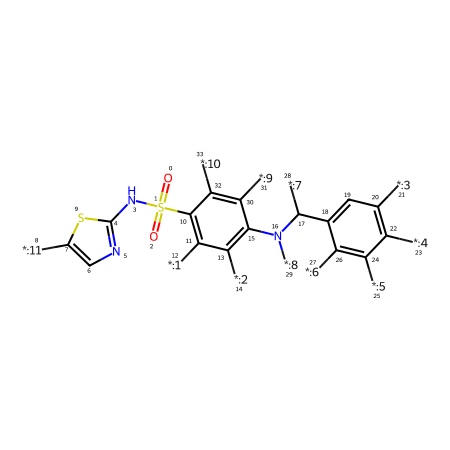

In [26]:
#drawing core 'O=S(=O)(Nc1ncc([*:11])s1)c1c([*:1])c([*:2])c(N(C(c2cc([*:3])c([*:4])c([*:5])c2[*:6])[*:7])[*:8])c([*:9])c1[*:10]'

drawer=Draw.MolDraw2DSVG(450,450)
opts=drawer.drawOptions()
opts.addAtomIndices=True

core_2 = subs_df_2['Core'][1]
core_2 = Chem.MolFromSmiles(core_2)

drawer.DrawMolecule(core_2)
drawer.FinishDrawing()
img=drawer.GetDrawingText()

SVG(img)

From the picture we see that the position 7 is not on the ring so it is discarded.
Positon 6 is ortho, also discarded.

In [27]:
#Getting values for the third scaffold group for core 'O=S(=O)(Nc1ncc([*:11])s1)c1c([*:1])c([*:2])c(N(C(c2cc([*:3])c([*:4])c([*:5])c2[*:6])[*:7])[*:8])c([*:9])c1[*:10]'
pattern = r'\[\*:\d+\]'
list_of_indexes=[]
for i,j in nav_longest_scafs_2[2][1]:
    list_of_indexes.append(j)

list_of_indexes
nls=subs_df_2.loc[subs_df_2.index.intersection(list_of_indexes)].copy()
nls['R3_stripped']=nls['R3']
nls['R3_stripped']=nls['R3_stripped'].str.replace(pattern,'',regex=True)
merged_4 = pd.merge(nls,values,how='inner',left_on='R3_stripped',right_on='substituent_smiles')
#if we look at the drawing of this core we see that the target substituents in position 3 are in meta position
merged_4['sigma_m'].agg(['min', 'max'])


min    0.00
max    0.43
Name: sigma_m, dtype: float64

In [28]:
#Looking at the next scaffold: O=S(=O)(Nc1cscn1)c1ccc(NCc2ccccc2CN2CCC2)cc1

nav_scaff_target_3 = nav_dataset['scaffold_column'].value_counts().index[2]
nav_scaff_target_mol_3 = Chem.MolFromSmiles(nav_scaff_target_3)

nav_scaff_target_df_3 = nav_dataset[nav_dataset['scaffold_column'] == nav_scaff_target_3].copy()
nav_scaff_target_df_3['molecule_objects'] = nav_scaff_target_df_3['canonical_smiles_nav16'].apply(Chem.MolFromSmiles)

subs_3, empty_pair = RGroupDecompose(cores=nav_scaff_target_mol_3, mols=nav_scaff_target_df_3['molecule_objects'], asSmiles=True, asRows=False)
subs_df_3 = pd.DataFrame(subs_3)
subs_df_3['molecule_chembl_id'] = nav_scaff_target_df_3['molecule_chembl_id'].tolist()

print(empty_pair)
nav_longest_scafs_3 = find_longest_sub_scaffold(subs_df_3)
nav_longest_scafs_3

[]


[('R1|F[*:1],R10|[H][*:10],R11|F[*:11],R2|[H][*:2],R4|[H][*:4],R5|[H][*:5],R6|[H][*:6],R7|[H][*:7],R8|[H][*:8],R9|F[*:9]',
  [('R3|[H][*:3]', 17),
   ('R3|FC(F)[*:3]', 20),
   ('R3|C[*:3]', 23),
   ('R3|C[*:3].F[*:3]', 27),
   ('R3|CCO[*:3].C[*:3]', 28),
   ('R3|CO[*:3]', 33),
   ('R3|CO[*:3].C[*:3]', 34),
   ('R3|F[*:3]', 36),
   ('R3|FC(F)(F)[*:3].O[*:3]', 38),
   ('R3|C[*:3].O[*:3]', 43)]),
 ('R1|F[*:1],R10|[H][*:10],R11|F[*:11],R2|[H][*:2],R3|[H][*:3],R4|[H][*:4],R5|[H][*:5],R6|[H][*:6],R7|[H][*:7],R8|[H][*:8]',
  [('R9|Cl[*:9]', 13),
   ('R9|F[*:9]', 17),
   ('R9|CC[*:9]', 19),
   ('R9|C[*:9]', 44),
   ('R9|[H][*:9]', 47),
   ('R9|CO[*:9]', 48)]),
 ('R1|F[*:1],R10|[H][*:10],R11|F[*:11],R3|[H][*:3],R4|[H][*:4],R5|[H][*:5],R6|[H][*:6],R7|[H][*:7],R8|[H][*:8],R9|F[*:9]',
  [('R2|Cl[*:2]', 15), ('R2|[H][*:2]', 17), ('R2|C[*:2]', 18)])]

In [29]:
subs_df_3.head()

,Core,R1,R10,R11,R2,R3,R4,R5,R6,R7,R8,R9,molecule_chembl_id
0,O=S(=O)(Nc1cscn1)c1c([*:11])cc(N(Cc2c(C(N3CC([...,[H][*:1],[H][*:10],F[*:11],Cl[*:2],[H][*:3],[H][*:4],[H][*:5],[H][*:6],[H][*:7],[H][*:8],F[*:9],CHEMBL4444000
1,O=S(=O)(Nc1cscn1)c1c([*:11])cc(N(Cc2c(C(N3CC([...,[H][*:1],[H][*:10],F[*:11],Cl[*:2],[H][*:3],C[*:4].C[*:4],[H][*:5],[H][*:6],[H][*:7],[H][*:8],F[*:9],CHEMBL4448084
2,O=S(=O)(Nc1cscn1)c1c([*:11])cc(N(Cc2c(C(N3CC([...,F[*:1],[H][*:10],F[*:11],[H][*:2],[H][*:3],C[*:4].C[*:4],[H][*:5],[H][*:6],[H][*:7],[H][*:8],F[*:9],CHEMBL4460028
3,O=S(=O)(Nc1cscn1)c1c([*:11])cc(N(Cc2c(C(N3CC([...,F[*:1],[H][*:10],F[*:11],F[*:2],[H][*:3],[H][*:4],[H][*:5],F[*:6],[H][*:7],[H][*:8],F[*:9],CHEMBL5748509
4,O=S(=O)(Nc1cscn1)c1c([*:11])cc(N(Cc2c(C(N3CC([...,F[*:1],[H][*:10],F[*:11],[H][*:2],[H][*:3],[H][*:4],C[*:5],[H][*:6],[H][*:7],[H][*:8],F[*:9],CHEMBL5752057


In [30]:
#smiles core

subs_df_3['Core'][1]

'O=S(=O)(Nc1cscn1)c1c([*:11])cc(N(Cc2c(C(N3CC([*:3])C3[*:4])[*:5])c([*:6])c([*:7])c([*:8])c2[*:9])[*:10])c([*:2])c1[*:1]'

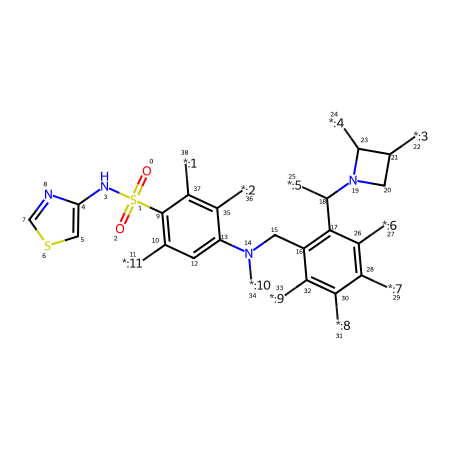

In [31]:
#drawing core 'O=S(=O)(Nc1cscn1)c1c([*:11])cc(N(Cc2c(C(N3CC([*:3])C3[*:4])[*:5])c([*:6])c([*:7])c([*:8])c2[*:9])[*:10])c([*:2])c1[*:1]'

drawer=Draw.MolDraw2DSVG(450,450)
opts=drawer.drawOptions()
opts.addAtomIndices=True

core_3 = subs_df_3['Core'][1]
core_3 = Chem.MolFromSmiles(core_3)

drawer.DrawMolecule(core_3)
drawer.FinishDrawing()
img=drawer.GetDrawingText()

SVG(img)



Position 3 is on the azetidine ring, so it is discarded.
Position 9 is ortho, so it is discarded.

In [32]:
#Getting values for the third scaffold group for core 'O=S(=O)(Nc1cscn1)c1c([*:11])cc(N(Cc2c(C(N3CC([*:3])C3[*:4])[*:5])c([*:6])c([*:7])c([*:8])c2[*:9])[*:10])c([*:2])c1[*:1]'

pattern = r'\[\*:\d+\]'
list_of_indexes=[]
for i,j in nav_longest_scafs_3[2][1]:
    list_of_indexes.append(j)

list_of_indexes
nls=subs_df_3.loc[subs_df_3.index.intersection(list_of_indexes)].copy()
nls['R2_stripped']=nls['R2']
nls['R2_stripped']=nls['R2_stripped'].str.replace(pattern,'',regex=True)
merged_6 = pd.merge(nls,values,how='inner',left_on='R2_stripped',right_on='substituent_smiles')
#if we look at the drawing of this core we see that the target substituents in position 2 are in meta position
merged_6['sigma_m'].agg(['min', 'max'])


min   -0.07
max    0.37
Name: sigma_m, dtype: float64

In [33]:
#Looking at the next scaffold: O=S(=O)(Nc1cscn1)c1ccc(NCc2ccccc2)cc1

nav_scaff_target_4 = nav_dataset['scaffold_column'].value_counts().index[3]
nav_scaff_target_mol_4 = Chem.MolFromSmiles(nav_scaff_target_4)

nav_scaff_target_df_4 = nav_dataset[nav_dataset['scaffold_column'] == nav_scaff_target_4].copy()
nav_scaff_target_df_4['molecule_objects'] = nav_scaff_target_df_4['canonical_smiles_nav16'].apply(Chem.MolFromSmiles)

subs_4, empty_pair = RGroupDecompose(cores=nav_scaff_target_mol_4, mols=nav_scaff_target_df_4['molecule_objects'], asSmiles=True, asRows=False)
subs_df_4 = pd.DataFrame(subs_4)
subs_df_4['molecule_chembl_id'] = nav_scaff_target_df_4['molecule_chembl_id'].tolist()

print(empty_pair)
nav_longest_scafs_4 = find_longest_sub_scaffold(subs_df_4)
nav_longest_scafs_4

[]


[('R1|[H][*:1],R10|F[*:10],R2|Cl[*:2],R3|[H][*:3],R5|[H][*:5],R6|[H][*:6],R7|F[*:7],R8|C[*:8],R9|[H][*:9]',
  [('R4|CO[*:4]', 1),
   ('R4|[H][*:4]', 7),
   ('R4|F[*:4]', 8),
   ('R4|N#C[*:4]', 9),
   ('R4|Cl[*:4]', 14),
   ('R4|FC(F)O[*:4]', 25),
   ('R4|O[*:4]', 32),
   ('R4|COC[*:4]', 42),
   ('R4|FC(F)C[*:4]', 44)]),
 ('R1|F[*:1],R10|F[*:10],R2|[H][*:2],R4|[H][*:4],R5|[H][*:5],R6|[H][*:6],R7|F[*:7],R8|[H][*:8],R9|[H][*:9]',
  [('R3|CC(C)N(C)C[*:3]', 0),
   ('R3|C[C@@H](O)[*:3]', 10),
   ('R3|CC(C)(C)NC[*:3]', 15),
   ('R3|CC(C)CN(C)C[*:3]', 28),
   ('R3|COCCN(C)C[*:3]', 35),
   ('R3|CCN(CC)C[*:3]', 41)]),
 ('R1|F[*:1],R10|F[*:10],R2|[H][*:2],R3|[H][*:3],R5|[H][*:5],R6|[H][*:6],R7|F[*:7],R8|C[*:8],R9|[H][*:9]',
  [('R4|N#C[*:4]', 3),
   ('R4|[H][*:4]', 4),
   ('R4|CO[*:4]', 6),
   ('R4|FC(F)[*:4]', 16),
   ('R4|Cl[*:4]', 27),
   ('R4|COC[*:4]', 31)])]

In [34]:
subs_df_4.head()

,Core,R1,R10,R2,R3,R4,R5,R6,R7,R8,R9,molecule_chembl_id
0,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(NC(c2c([*...,F[*:1],F[*:10],[H][*:2],CC(C)N(C)C[*:3],[H][*:4],[H][*:5],[H][*:6],F[*:7],[H][*:8],[H][*:9],CHEMBL4435054
1,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(NC(c2c([*...,[H][*:1],F[*:10],Cl[*:2],[H][*:3],CO[*:4],[H][*:5],[H][*:6],F[*:7],C[*:8],[H][*:9],CHEMBL4445144
2,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(NC(c2c([*...,[H][*:1],F[*:10],Cl[*:2],[H][*:3],F[*:4],[H][*:5],[H][*:6],F[*:7],[H][*:8],[H][*:9],CHEMBL4450313
3,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(NC(c2c([*...,F[*:1],F[*:10],[H][*:2],[H][*:3],N#C[*:4],[H][*:5],[H][*:6],F[*:7],C[*:8],[H][*:9],CHEMBL4459170
4,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(NC(c2c([*...,F[*:1],F[*:10],[H][*:2],[H][*:3],[H][*:4],[H][*:5],[H][*:6],F[*:7],C[*:8],[H][*:9],CHEMBL4466858


In [35]:
#smiles core

subs_df_4['Core'][1]

'O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(NC(c2c([*:3])c([*:4])c([*:5])c([*:6])c2[*:7])[*:8])c([*:9])c1[*:10]'

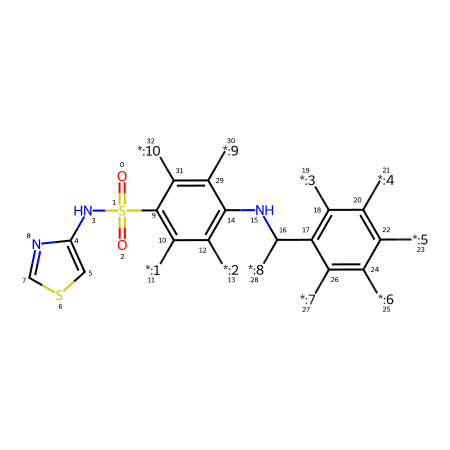

In [36]:
#drawing core 'O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(NC(c2c([*:3])c([*:4])c([*:5])c([*:6])c2[*:7])[*:8])c([*:9])c1[*:10]'

drawer=Draw.MolDraw2DSVG(450,450)
opts=drawer.drawOptions()
opts.addAtomIndices=True

core_4 = subs_df_4['Core'][1]
core_4 = Chem.MolFromSmiles(core_4)

drawer.DrawMolecule(core_4)
drawer.FinishDrawing()
img=drawer.GetDrawingText()

SVG(img)


Position 3 is ortho so it is discarded.

In [37]:
#Getting values for the first scaffold group for core 'O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(NC(c2c([*:3])c([*:4])c([*:5])c([*:6])c2[*:7])[*:8])c([*:9])c1[*:10]'

pattern = r'\[\*:\d+\]'
list_of_indexes=[]
for i,j in nav_longest_scafs_4[0][1]:
    list_of_indexes.append(j)

list_of_indexes
nls=subs_df_4.loc[subs_df_4.index.intersection(list_of_indexes)].copy()
nls['R4_stripped']=nls['R4']
nls['R4_stripped']=nls['R4_stripped'].str.replace(pattern,'',regex=True)
merged_7 = pd.merge(nls,values,how='inner',left_on='R4_stripped',right_on='substituent_smiles')
#if we look at the drawing of this core we see that the target substituents in position 4 are in meta position
merged_7['sigma_m'].agg(['min', 'max'])


min    0.00
max    0.56
Name: sigma_m, dtype: float64

In [38]:
#Getting values for the third scaffold group for core 'O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(NC(c2c([*:3])c([*:4])c([*:5])c([*:6])c2[*:7])[*:8])c([*:9])c1[*:10]'

pattern = r'\[\*:\d+\]'
list_of_indexes=[]
for i,j in nav_longest_scafs_4[2][1]:
    list_of_indexes.append(j)

list_of_indexes
nls=subs_df_4.loc[subs_df_4.index.intersection(list_of_indexes)].copy()
nls['R4_stripped']=nls['R4']
nls['R4_stripped']=nls['R4_stripped'].str.replace(pattern,'',regex=True)
merged_8 = pd.merge(nls,values,how='inner',left_on='R4_stripped',right_on='substituent_smiles')
#if we look at the drawing of this core we see that the target substituents in position 4 are in meta position
merged_8['sigma_m'].agg(['min', 'max'])


min    0.00
max    0.56
Name: sigma_m, dtype: float64

In [39]:
#Looking at the next scaffold: O=S(=O)(Nc1nccs1)c1ccc(OC2CCN(Cc3ccccc3)CC2)cc1

nav_scaff_target_5 = nav_dataset['scaffold_column'].value_counts().index[4]
nav_scaff_target_mol_5 = Chem.MolFromSmiles(nav_scaff_target_5)

nav_scaff_target_df_5 = nav_dataset[nav_dataset['scaffold_column'] == nav_scaff_target_5].copy()
nav_scaff_target_df_5['molecule_objects'] = nav_scaff_target_df_5['canonical_smiles_nav16'].apply(Chem.MolFromSmiles)

subs_5, empty_pair = RGroupDecompose(cores=nav_scaff_target_mol_5, mols=nav_scaff_target_df_5['molecule_objects'], asSmiles=True, asRows=False)
subs_df_5 = pd.DataFrame(subs_5)
subs_df_5['molecule_chembl_id'] = nav_scaff_target_df_5['molecule_chembl_id'].tolist()

print(empty_pair)
nav_longest_scafs_5 = find_longest_sub_scaffold(subs_df_5)
nav_longest_scafs_5

[]


[('R1|[H][*:1],R10|Cl[*:10],R11|[H][*:11],R2|[H][*:2],R3|[H][*:3],R5|[H][*:5],R6|[H][*:6],R7|[H][*:7],R8|[H][*:8],R9|[H][*:9]',
  [('R4|F[*:4]', 0),
   ('R4|FC(F)O[*:4]', 2),
   ('R4|FC(F)[*:4]', 21),
   ('R4|CO[*:4]', 26),
   ('R4|C[*:4]', 27),
   ('R4|[H][*:4]', 31),
   ('R4|Cl[*:4]', 34)]),
 ('R1|[H][*:1],R10|Cl[*:10],R11|[H][*:11],R2|[H][*:2],R3|[H][*:3],R4|[H][*:4],R6|[H][*:6],R7|[H][*:7],R8|[H][*:8],R9|[H][*:9]',
  [('R5|C[*:5]', 8),
   ('R5|Cl[*:5]', 18),
   ('R5|F[*:5]', 19),
   ('R5|FC(F)(F)[*:5]', 23),
   ('R5|[H][*:5]', 31)]),
 ('R10|Cl[*:10],R11|[H][*:11],R2|[H][*:2],R3|[H][*:3],R4|[H][*:4],R5|[H][*:5],R6|C[*:6],R7|[H][*:7],R8|[H][*:8],R9|[H][*:9]',
  [('R1|[H][*:1]', 3),
   ('R1|[H][*:1]', 10),
   ('R1|F[*:1]', 11),
   ('R1|F[*:1]', 16)])]

In [40]:
subs_df_5.head()

,Core,R1,R10,R11,R2,R3,R4,R5,R6,R7,R8,R9,molecule_chembl_id
0,O=S(=O)(Nc1nccs1)c1c([*:1])cc(OC2([*:9])CCN(C(...,[H][*:1],Cl[*:10],[H][*:11],[H][*:2],[H][*:3],F[*:4],[H][*:5],[H][*:6],[H][*:7],[H][*:8],[H][*:9],CHEMBL5750754
1,O=S(=O)(Nc1nccs1)c1c([*:1])cc(OC2([*:9])CCN(C(...,F[*:1],C[*:10],F[*:11],[H][*:2],[H][*:3],[H][*:4],[H][*:5],[H][*:6],[H][*:7],[H][*:8],[H][*:9],CHEMBL5751525
2,O=S(=O)(Nc1nccs1)c1c([*:1])cc(OC2([*:9])CCN(C(...,[H][*:1],Cl[*:10],[H][*:11],[H][*:2],[H][*:3],FC(F)O[*:4],[H][*:5],[H][*:6],[H][*:7],[H][*:8],[H][*:9],CHEMBL5776986
3,O=S(=O)(Nc1nccs1)c1c([*:1])cc(OC2([*:9])CCN(C(...,[H][*:1],Cl[*:10],[H][*:11],[H][*:2],[H][*:3],[H][*:4],[H][*:5],C[*:6],[H][*:7],[H][*:8],[H][*:9],CHEMBL5782612
4,O=S(=O)(Nc1nccs1)c1c([*:1])cc(OC2([*:9])CCN(C(...,[H][*:1],Cl[*:10],[H][*:11],[H][*:2],[H][*:3],[H][*:4],[H][*:5],C[*:6].C[*:6],[H][*:7],[H][*:8],[H][*:9],CHEMBL5785083


In [41]:
#smiles core

subs_df_5['Core'][1]

'O=S(=O)(Nc1nccs1)c1c([*:1])cc(OC2([*:9])CCN(C(c3cc([*:2])c([*:3])c([*:4])c3[*:5])[*:6])C([*:7])C2[*:8])c([*:10])c1[*:11]'

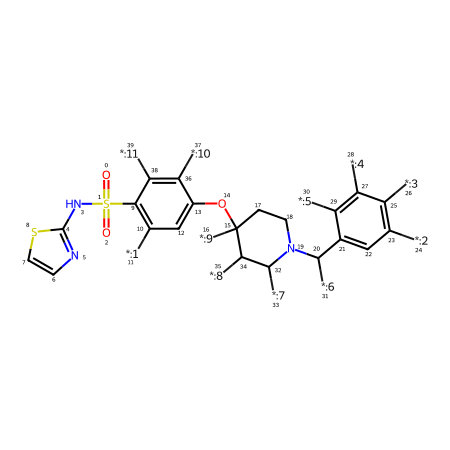

In [42]:
#drawing core 'O=S(=O)(Nc1nccs1)c1c([*:1])cc(OC2([*:9])CCN(C(c3cc([*:2])c([*:3])c([*:4])c3[*:5])[*:6])C([*:7])C2[*:8])c([*:10])c1[*:11]'

drawer=Draw.MolDraw2DSVG(450,450)
opts=drawer.drawOptions()
opts.addAtomIndices=True

core_5 = subs_df_5['Core'][1]
core_5 = Chem.MolFromSmiles(core_5)

drawer.DrawMolecule(core_5)
drawer.FinishDrawing()
img=drawer.GetDrawingText()

SVG(img)


In [43]:
#Getting values for the first scaffold group for core 'O=S(=O)(Nc1nccs1)c1c([*:1])cc(OC2([*:9])CCN(C(c3cc([*:2])c([*:3])c([*:4])c3[*:5])[*:6])C([*:7])C2[*:8])c([*:10])c1[*:11]'

pattern = r'\[\*:\d+\]'
list_of_indexes=[]
for i,j in nav_longest_scafs_5[0][1]:
    list_of_indexes.append(j)

list_of_indexes
nls=subs_df_5.loc[subs_df_5.index.intersection(list_of_indexes)].copy()
nls['R4_stripped']=nls['R4']
nls['R4_stripped']=nls['R4_stripped'].str.replace(pattern,'',regex=True)
merged_8 = pd.merge(nls,values,how='inner',left_on='R4_stripped',right_on='substituent_smiles')
#if we look at the drawing of this core we see that the target substituents in position 4 are in meta position
merged_8['sigma_m'].agg(['min', 'max'])


min   -0.07
max    0.37
Name: sigma_m, dtype: float64

With the shrinking of the lists of subsituents for Nav dataset,further analysis of scaffolds will not be done.

### Nav Hammett feasibility screen

* Murcko scaffold binning (`includeChirality=False`), then decomposition of every R group. 
* For the five biggest scaffolds every analysis was done by the method of leave-one-position-out, to find the scaffold with most varying attachments from both donors and acceptors in the same position.
* They had to satisfy pre-registered gate, defined at the start of the notebook.

| Scaffold | Position | Ring site | n | σ used | Span | Verdict |
|---|---|---|---|---|---|---|
| 1 | R6 | benzyl, meta | 11 → 10 | σ_m | 0.00 to 0.43 | fail — narrow, no donors |
| 1 | R5 | benzyl, para | 8 | σ_p | −0.83 to 0.23 | **pass** |
| 1 | R2 | central, meta | 7 | σ_m | −0.07 to 0.39 | fail — narrow, no donors |
| 2 | R7 | benzylic carbon | 15 | — | — | fail — not ring-attached |
| 2 | R6 | pendant, ortho | 7 | — | — | fail — no σ for ortho |
| 2 | R3 | pendant, meta | 6 | σ_m | — | fail — narrow |
| 3 | R3 | azetidine | 10 | — | — | fail — not aromatic |
| 3 | R9 | pendant, ortho | 6 | — | — | fail — ortho; ring bears two scaffold attachments, reference undefined |
| 3 | R2 | central, meta | 3 | σ_m | −0.07 to 0.37 | fail — count |
| 4 | R4 | pendant, meta | 9 → 7 | σ_m | 0.00 to 0.56 | fail — no donors |
| 4 | R3 | pendant, ortho | 6 | — | — | fail — ortho, aminoalkyl |
| 4 | R4 (2nd background) | pendant, meta | 6 → 5 | σ_m | 0.00 to 0.56 | fail — count after exclusions |
| 5 | R4 | pendant, meta | 7 | σ_m | −0.07 to 0.37 | fail — narrow, no donors |
| 5 | R5 | pendant, ortho | 5 | — | — | fail — ortho |
| 5 | R1 | central, ortho | 4 | — | — | fail — ortho |

* For the Hammett analysis only scaffold 1 in position 5 satisfied all the criteria.

* Known limitation is that the substituent NMe₂ is carrying the biggest difference in the electronegativity for electron donors. In the literature the value of σ_p ranges from -0.21 all the way to -1.05. Inside the used literature for this project value for σ_p was -0.83. Without it the interval is only 0.36 wide and would not pass the criteria.

* Meta positions failed due to the nature of the resonance. Inside the aromatic ring, meta position substituents cannot be reached through resonance, only ortho and para positions can. This means that meta position donors cannot express their strong electron donating nature. This is why for most of the table we see 0 or close to 0 as the start of the interval. This is why the only passing group is with the para position.

* Inside the table there are arrows that point from higher to lower number. This means that some substituents were dropped because there was no recorded value for this substituent inside the source literature for this project.

* n is the number of compounds, not the distinct substituents.

In [44]:
#merging two tables to get full data in one table

hc = pd.merge(left=merged_2,right=nav_dataset,how='inner',on='molecule_chembl_id')
hc.head(10)

#there are two entries with [H] substituent - possible enantiomers

,Core,R1,R10,R11,R12,R13,R2,R3,R4,R5,...,substituent_name,sigma_m,sigma_p,F,R,ref,pchembl_value_nav11,pchembl_value_nav16,canonical_smiles_nav16,scaffold_column
0,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],CN(C)[*:5],...,dimethylamino group,-0.16,-0.83,0.15,-0.98,"185,183",5.10,5.08,CN(C)c1ccc(CN2CC[C@H](N(C)c3cc(F)c(S(=O)(=O)Nc...,O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1
1,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],[H][*:5],...,hydrogen,0.00,0.00,0.03,0.00,no quotation,4.75,5.71,CN(c1cc(F)c(S(=O)(=O)Nc2cscn2)cc1Cl)[C@H]1CCN(...,O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1
2,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],Br[*:5],...,bromo substituent,0.39,0.23,0.45,-0.22,183,5.34,5.25,CN(c1cc(F)c(S(=O)(=O)Nc2cscn2)cc1Cl)[C@H]1CCN(...,O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1
3,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],C[*:5],...,methyl group,-0.07,-0.17,0.01,-0.18,183,5.24,5.48,Cc1ccc(CN2CC[C@H](N(C)c3cc(F)c(S(=O)(=O)Nc4csc...,O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1
4,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],CCC[*:5],...,propyl group,-0.06,-0.13,0.01,-0.14,"85,87",5.63,5.73,CCCc1ccc(CN2CC[C@H](N(C)c3cc(F)c(S(=O)(=O)Nc4c...,O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1
5,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],Cl[*:5],...,chloro substituent,0.37,0.23,0.42,-0.19,183,5.49,5.38,CN(c1cc(F)c(S(=O)(=O)Nc2cscn2)cc1Cl)[C@H]1CCN(...,O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1
6,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@]2([...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],[H][*:5],...,hydrogen,0.00,0.00,0.03,0.00,no quotation,4.60,4.88,CN(c1cc(F)c(S(=O)(=O)Nc2cscn2)cc1Cl)[C@@H]1CCN...,O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1
7,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],F[*:5],...,fluoro substituent,0.34,0.06,0.45,-0.39,183,4.77,5.28,CN(c1cc(F)c(S(=O)(=O)Nc2cscn2)cc1Cl)[C@H]1CCN(...,O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1


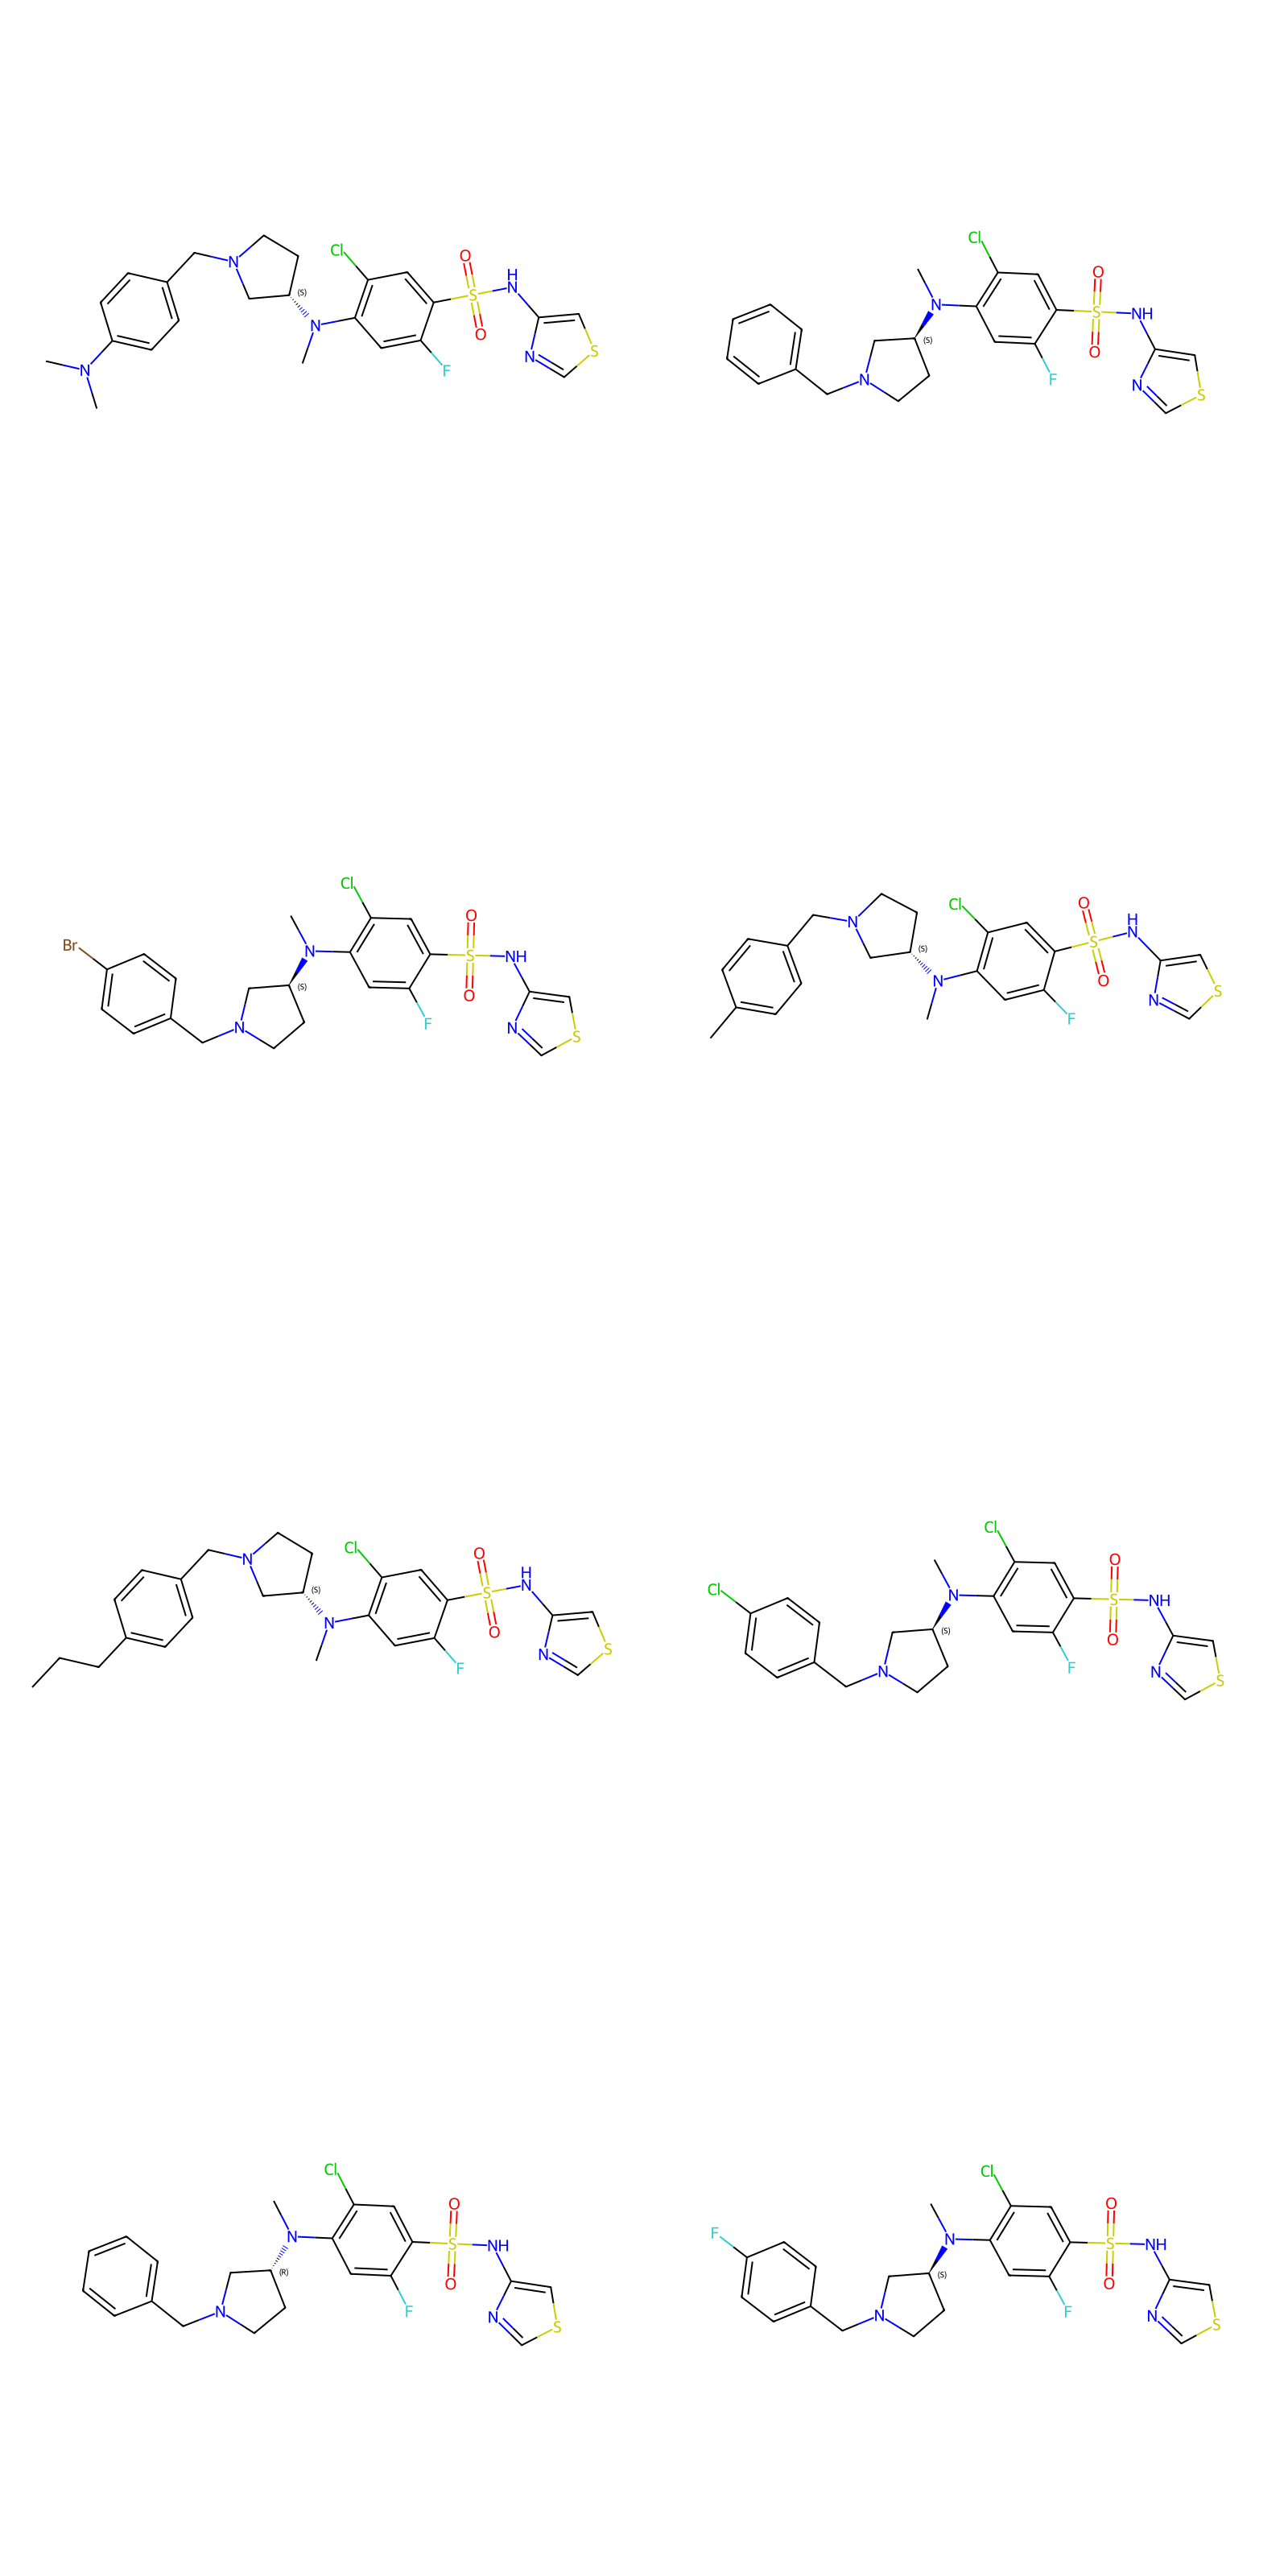

In [45]:
#drawing molecules from the selected group


mols_from_sg=[]

for mol in hc['canonical_smiles_nav16']:
        mols_from_sg.append(Chem.MolFromSmiles(mol))

opts = Draw.rdMolDraw2D.MolDrawOptions()
opts.addStereoAnnotation = True

img = Draw.MolsToGridImage(
        mols=mols_from_sg, 
        subImgSize=(800,800),
        returnPNG=False,
        molsPerRow=2,
        drawOptions=opts
                      )
img

Dropping the R enantiomer, to keep stereochemistry constant inside the whole series

In [46]:

hc.drop(index=6, inplace=True)
len(hc)

7

In [47]:
hc.head(10)

,Core,R1,R10,R11,R12,R13,R2,R3,R4,R5,...,substituent_name,sigma_m,sigma_p,F,R,ref,pchembl_value_nav11,pchembl_value_nav16,canonical_smiles_nav16,scaffold_column
0,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],CN(C)[*:5],...,dimethylamino group,-0.16,-0.83,0.15,-0.98,"185,183",5.10,5.08,CN(C)c1ccc(CN2CC[C@H](N(C)c3cc(F)c(S(=O)(=O)Nc...,O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1
1,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],[H][*:5],...,hydrogen,0.00,0.00,0.03,0.00,no quotation,4.75,5.71,CN(c1cc(F)c(S(=O)(=O)Nc2cscn2)cc1Cl)[C@H]1CCN(...,O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1
2,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],Br[*:5],...,bromo substituent,0.39,0.23,0.45,-0.22,183,5.34,5.25,CN(c1cc(F)c(S(=O)(=O)Nc2cscn2)cc1Cl)[C@H]1CCN(...,O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1
3,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],C[*:5],...,methyl group,-0.07,-0.17,0.01,-0.18,183,5.24,5.48,Cc1ccc(CN2CC[C@H](N(C)c3cc(F)c(S(=O)(=O)Nc4csc...,O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1
4,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],CCC[*:5],...,propyl group,-0.06,-0.13,0.01,-0.14,"85,87",5.63,5.73,CCCc1ccc(CN2CC[C@H](N(C)c3cc(F)c(S(=O)(=O)Nc4c...,O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1
5,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],Cl[*:5],...,chloro substituent,0.37,0.23,0.42,-0.19,183,5.49,5.38,CN(c1cc(F)c(S(=O)(=O)Nc2cscn2)cc1Cl)[C@H]1CCN(...,O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1
7,O=S(=O)(Nc1cscn1)c1c([*:1])c([*:2])c(N([C@@]2(...,[H][*:1],[H][*:10],C[*:11],[H][*:12],F[*:13],Cl[*:2],[H][*:3],[H][*:4],F[*:5],...,fluoro substituent,0.34,0.06,0.45,-0.39,183,4.77,5.28,CN(c1cc(F)c(S(=O)(=O)Nc2cscn2)cc1Cl)[C@H]1CCN(...,O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1


In [48]:
#Exporting dataset for Hammett calculation



hc.to_csv(PROCESSED / 'hammett_candidates.csv')

In [49]:
#finding biggest scaffold molecule inside serotonin dataset

ser_scaffold = []

for mol in ser_cleaned:

    smiles = Chem.MolToSmiles(mol)
    scaffold = MurckoScaffold.MurckoScaffoldSmiles(smiles, includeChirality=False)
    ser_scaffold.append(scaffold)

ser_dataset['cleaned_mols'] = ser_cleaned

ser_dataset['scaffold_column'] = ser_scaffold

ser_dataset['scaffold_column'].value_counts()[0:10]

scaffold_column
c1ccc2[nH]ccc2c1                                  36
c1cc2c3c(ccc2[nH]1)CCCC3                          35
O=C1COc2ccc(CC3CCN(CCOc4cccc5ncccc45)CC3)cc2N1    20
c1ccc(CN2CCN(CCOc3cccc4ncccc34)CC2)cc1            15
O=C(Nc1cccc(N2CCNCC2)c1)N1CCN(c2ccccc2)CC1        14
O=C1COc2ccc(CCN3CCN(c4cccc5ncccc45)CC3)cc2N1      14
c1ccc(CCN2CCN(c3cccc4ncccc34)CC2)cc1              13
c1ccccc1                                          11
c1ccc(-c2ccccc2)cc1                               11
c1ccc(CC2CCN(CCOc3cccc4ncccc34)CC2)cc1            11
Name: count, dtype: int64

In [50]:
#Looking at the next scaffold: c1ccc2[nH]ccc2c1  

ser_scaff_target_6 = ser_dataset['scaffold_column'].value_counts().index[0]
ser_scaff_target_mol_6 = Chem.MolFromSmiles(ser_scaff_target_6)

ser_scaff_target_df_6 = ser_dataset[ser_dataset['scaffold_column'] == ser_scaff_target_6].copy()

subs_6, empty_pair = RGroupDecompose(cores=ser_scaff_target_mol_6, mols=ser_scaff_target_df_6['cleaned_mols'], asSmiles=True, asRows=False)

subs_df_6 = pd.DataFrame(subs_6)
subs_df_6['molecule_chembl_id'] = ser_scaff_target_df_6['molecule_chembl_id'].tolist()

print(empty_pair)
ser_longest_scafs_1 = find_longest_sub_scaffold(subs_df_6)
ser_longest_scafs_1

[]


[('R1|[H][*:1],R2|NCC[*:2],R3|[H][*:3]',
  [('R4|CC[*:4]', 0),
   ('R4|CCCCCCCCCCCO[*:4]', 2),
   ('R4|CC(=O)[*:4]', 3),
   ('R4|CC(C)(C)CCCCCCO[*:4]', 4),
   ('R4|CC(C)CCCCCCO[*:4]', 5),
   ('R4|CCCCCCCCCCO[*:4]', 6),
   ('R4|CCCCCO[*:4]', 7),
   ('R4|O=S(=O)(O[*:4])C(F)(F)F', 10),
   ('R4|CCCCCCCO[*:4]', 18),
   ('R4|CCCCCCCCO[*:4]', 21),
   ('R4|O[*:4]', 28),
   ('R4|CCCCCCCCCC[*:4]', 29),
   ('R4|[H][*:4]', 33),
   ('R4|CO[*:4]', 34),
   ('R4|CCCCCCCCCO[*:4]', 35)]),
 ('R1|[H][*:1],R2|CN(C)CC[*:2],R3|[H][*:3]',
  [('R4|CC(C)(C)C(=O)O[*:4]', 1),
   ('R4|CNS(=O)(=O)C[*:4]', 8),
   ('R4|O=S(=O)(O[*:4])C(F)(F)F', 11),
   ('R4|CC(C)[*:4]', 15),
   ('R4|CCCCCCCCCO[*:4]', 19),
   ('R4|CCC(=O)O[*:4]', 20),
   ('R4|CC(C)C(=O)O[*:4]', 22),
   ('R4|CC[*:4]', 31)]),
 ('R1|[H][*:1],R2|C=CCN(CC=C)CC[*:2],R3|[H][*:3]',
  [('R4|CO[*:4]', 13),
   ('R4|Cl[*:4]', 24),
   ('R4|C[*:4]', 25),
   ('R4|Br[*:4]', 26),
   ('R4|F[*:4]', 27)])]

In [51]:
subs_df_6.head()

,Core,R1,R2,R3,R4,molecule_chembl_id
0,c1cc2[nH]c([*:3])c([*:2])c2c([*:1])c1[*:4],[H][*:1],NCC[*:2],[H][*:3],CC[*:4],CHEMBL107511
1,c1cc2[nH]c([*:3])c([*:2])c2c([*:1])c1[*:4],[H][*:1],CN(C)CC[*:2],[H][*:3],CC(C)(C)C(=O)O[*:4],CHEMBL109360
2,c1cc2[nH]c([*:3])c([*:2])c2c([*:1])c1[*:4],[H][*:1],NCC[*:2],[H][*:3],CCCCCCCCCCCO[*:4],CHEMBL109839
3,c1cc2[nH]c([*:3])c([*:2])c2c([*:1])c1[*:4],[H][*:1],NCC[*:2],[H][*:3],CC(=O)[*:4],CHEMBL110317
4,c1cc2[nH]c([*:3])c([*:2])c2c([*:1])c1[*:4],[H][*:1],NCC[*:2],[H][*:3],CC(C)(C)CCCCCCO[*:4],CHEMBL111150


In [52]:
#smiles core

subs_df_6['Core'][1]

'c1cc2[nH]c([*:3])c([*:2])c2c([*:1])c1[*:4]'

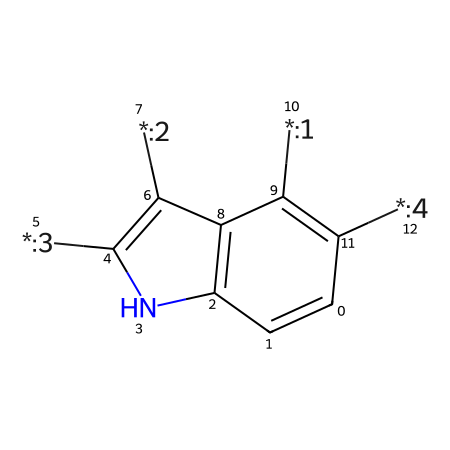

In [53]:
#drawing core 'c1cc2[nH]c([*:3])c([*:2])c2c([*:1])c1[*:4]'

drawer=Draw.MolDraw2DSVG(450,450)
opts=drawer.drawOptions()
opts.addAtomIndices=True

core_6 = subs_df_6['Core'][1]
core_6 = Chem.MolFromSmiles(core_6)

drawer.DrawMolecule(core_6)
drawer.FinishDrawing()
img=drawer.GetDrawingText()

SVG(img)


Core is fused heteroaromatics with no single benzene ring and no single attachment to count from. All three groups discarded.

In [54]:
#Looking at the next scaffold: c1cc2c3c(ccc2[nH]1)CCCC3

ser_scaff_target_7 = ser_dataset['scaffold_column'].value_counts().index[1]
ser_scaff_target_mol_7 = Chem.MolFromSmiles(ser_scaff_target_7)

ser_scaff_target_df_7 = ser_dataset[ser_dataset['scaffold_column'] == ser_scaff_target_7].copy()

subs_7, empty_pair = RGroupDecompose(cores=ser_scaff_target_mol_7, mols=ser_scaff_target_df_7['cleaned_mols'], asSmiles=True, asRows=False)
subs_df_7 = pd.DataFrame(subs_7)
subs_df_7['molecule_chembl_id'] = ser_scaff_target_df_7['molecule_chembl_id'].tolist()

print(empty_pair)
ser_longest_scafs_2 = find_longest_sub_scaffold(subs_df_7)
ser_longest_scafs_2

[]


[('R1|CCCN(CCC)[*:1],R2|[H][*:2],R3|[H][*:3]',
  [('R4|[H][*:4]', 3),
   ('R4|[H][*:4]', 4),
   ('R4|O=C(C(F)(F)F)[*:4]', 5),
   ('R4|CS(=O)(=O)[*:4]', 6),
   ('R4|O=C[*:4]', 8),
   ('R4|NC(=O)C(=O)[*:4]', 12),
   ('R4|O=C[*:4]', 13),
   ('R4|N#C[*:4]', 14),
   ('R4|[H][*:4]', 18),
   ('R4|C[*:4]', 19),
   ('R4|NC(=O)C(=O)[*:4]', 20),
   ('R4|N#C[*:4]', 21),
   ('R4|NC(=O)C(=O)[*:4]', 25),
   ('R4|CC(=O)[*:4]', 28),
   ('R4|O=C[*:4]', 31),
   ('R4|N#C[*:4]', 33),
   ('R4|FC(F)(F)C[*:4]', 34)]),
 ('R2|[H][*:2],R3|[H][*:3],R4|[H][*:4]',
  [('R1|CCCN(CC(C)C)[*:1]', 1),
   ('R1|CN(C)[*:1]', 2),
   ('R1|CCCN(CCC)[*:1]', 3),
   ('R1|CCCN(CCC)[*:1]', 4),
   ('R1|CN(C)[*:1]', 7),
   ('R1|CCCN[*:1]', 11),
   ('R1|CN(C)[*:1]', 16),
   ('R1|CCCN(CCC)[*:1]', 18)]),
 ('R1|CCCN(CCC)[*:1],R2|[H][*:2],R3|F[*:3]',
  [('R4|[H][*:4]', 9),
   ('R4|[H][*:4]', 10),
   ('R4|O=C[*:4]', 17),
   ('R4|O=C[*:4]', 22),
   ('R4|[H][*:4]', 23),
   ('R4|N#C[*:4]', 30),
   ('R4|CCC[*:4]', 32)])]

In [55]:
subs_df_7.head()

,Core,R1,R2,R3,R4,molecule_chembl_id
0,c1c2c(c3c([*:4])cn([*:2])c3c1[*:3])CC([*:1])CC2,CN(C)[*:1],[H][*:2],[H][*:3],O=C[*:4],CHEMBL1744040
1,c1c2c(c3c([*:4])cn([*:2])c3c1[*:3])CC([*:1])CC2,CCCN(CC(C)C)[*:1],[H][*:2],[H][*:3],[H][*:4],CHEMBL1744041
2,c1c2c(c3c([*:4])cn([*:2])c3c1[*:3])CC([*:1])CC2,CN(C)[*:1],[H][*:2],[H][*:3],[H][*:4],CHEMBL292274
3,c1c2c(c3c([*:4])cn([*:2])c3c1[*:3])CC([*:1])CC2,CCCN(CCC)[*:1],[H][*:2],[H][*:3],[H][*:4],CHEMBL302171
4,c1c2c(c3c([*:4])cn([*:2])c3c1[*:3])CC([*:1])CC2,CCCN(CCC)[*:1],[H][*:2],[H][*:3],[H][*:4],CHEMBL302172


In [56]:
#smiles core

subs_df_7['Core'][1]

'c1c2c(c3c([*:4])cn([*:2])c3c1[*:3])CC([*:1])CC2'

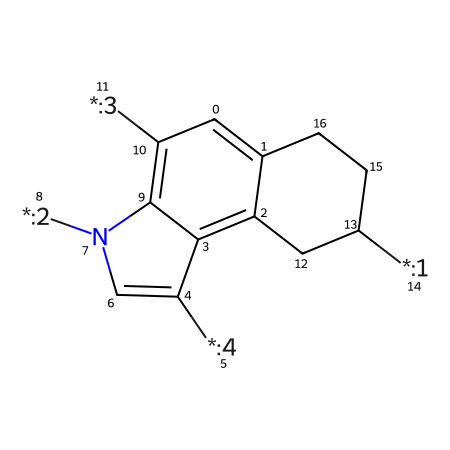

In [57]:
#drawing core 'c1c2c(c3c([*:4])cn([*:2])c3c1[*:3])CC([*:1])CC2'

drawer=Draw.MolDraw2DSVG(450,450)
opts=drawer.drawOptions()
opts.addAtomIndices=True

core_7 = subs_df_7['Core'][1]
core_7 = Chem.MolFromSmiles(core_7)

drawer.DrawMolecule(core_7)
drawer.FinishDrawing()
img=drawer.GetDrawingText()

SVG(img)


Core is fused heteroaromatics with no single benzene ring and no single attachment to count from. All three groups discarded.

In [58]:
#Looking at the next scaffold: O=C1COc2ccc(CC3CCN(CCOc4cccc5ncccc45)CC3)cc2N1

ser_scaff_target_8 = ser_dataset['scaffold_column'].value_counts().index[2]
ser_scaff_target_mol_8 = Chem.MolFromSmiles(ser_scaff_target_8)

ser_scaff_target_df_8 = ser_dataset[ser_dataset['scaffold_column'] == ser_scaff_target_8].copy()

subs_8, empty_pair = RGroupDecompose(cores=ser_scaff_target_mol_8, mols=ser_scaff_target_df_8['cleaned_mols'], asSmiles=True, asRows=False)
subs_df_8 = pd.DataFrame(subs_8)
subs_df_8['molecule_chembl_id'] = ser_scaff_target_df_8['molecule_chembl_id'].tolist()

print(empty_pair)
ser_longest_scafs_3 = find_longest_sub_scaffold(subs_df_8)
ser_longest_scafs_3

[]


[('R10|[H][*:10],R2|[H][*:2],R3|C[*:3],R4|[H][*:4],R5|[H][*:5],R6|[H][*:6],R7|[H][*:7],R8|[H][*:8],R9|[H][*:9]',
  [('R1|[H][*:1]', 0),
   ('R1|C[*:1]', 12),
   ('R1|CC[*:1]', 13),
   ('R1|CC(C)[*:1]', 14)]),
 ('R1|[H][*:1],R10|[H][*:10],R2|[H][*:2],R3|C[*:3],R5|[H][*:5],R6|[H][*:6],R7|[H][*:7],R8|[H][*:8],R9|[H][*:9]',
  [('R4|[H][*:4]', 0), ('R4|F[*:4]', 9), ('R4|Cl[*:4]', 10)]),
 ('R1|[H][*:1],R10|[H][*:10],R2|[H][*:2],R3|C[*:3],R4|[H][*:4],R6|[H][*:6],R7|[H][*:7],R8|[H][*:8],R9|[H][*:9]',
  [('R5|[H][*:5]', 0), ('R5|Cl[*:5]', 5), ('R5|N#C[*:5]', 6)])]

In [59]:
subs_df_8.head()

,Core,R1,R10,R2,R3,R4,R5,R6,R7,R8,R9,molecule_chembl_id
0,O=C1COc2c(c([*:2])c(CC3CCN(C(C(Oc4c([*:6])c([*...,[H][*:1],[H][*:10],[H][*:2],C[*:3],[H][*:4],[H][*:5],[H][*:6],[H][*:7],[H][*:8],[H][*:9],CHEMBL183460
1,O=C1COc2c(c([*:2])c(CC3CCN(C(C(Oc4c([*:6])c([*...,[H][*:1],[H][*:10],F[*:2],C[*:3],[H][*:4],Cl[*:5],[H][*:6],[H][*:7],[H][*:8],[H][*:9],CHEMBL238519
2,O=C1COc2c(c([*:2])c(CC3CCN(C(C(Oc4c([*:6])c([*...,[H][*:1],[H][*:10],[H][*:2],C[*:3],[H][*:4],F[*:5],[H][*:6],[H][*:7],[H][*:8],F[*:9],CHEMBL238520
3,O=C1COc2c(c([*:2])c(CC3CCN(C(C(Oc4c([*:6])c([*...,[H][*:1],F[*:10],[H][*:2],C[*:3],[H][*:4],F[*:5],[H][*:6],[H][*:7],[H][*:8],[H][*:9],CHEMBL238730
4,O=C1COc2c(c([*:2])c(CC3CCN(C(C(Oc4c([*:6])c([*...,[H][*:1],F[*:10],[H][*:2],C[*:3],[H][*:4],Cl[*:5],[H][*:6],[H][*:7],[H][*:8],[H][*:9],CHEMBL238732


In [60]:
#smiles core

subs_df_8['Core'][1]

'O=C1COc2c(c([*:2])c(CC3CCN(C(C(Oc4c([*:6])c([*:5])c([*:4])c5nc([*:3])ccc45)[*:7])[*:8])CC3)c([*:9])c2[*:10])N1[*:1]'

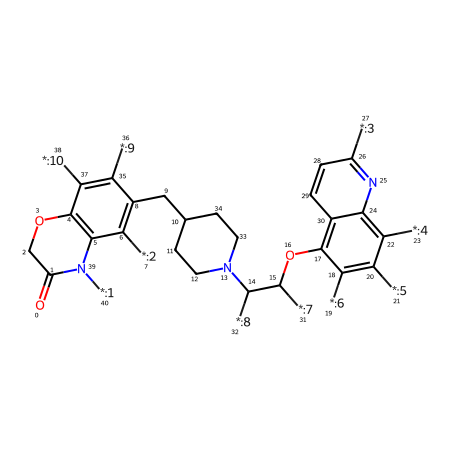

In [61]:
#drawing core 'O=C1COc2c(c([*:2])c(CC3CCN(C(C(Oc4c([*:6])c([*:5])c([*:4])c5nc([*:3])ccc45)[*:7])[*:8])CC3)c([*:9])c2[*:10])N1[*:1]'

drawer=Draw.MolDraw2DSVG(450,450)
opts=drawer.drawOptions()
opts.addAtomIndices=True

core_8 = subs_df_8['Core'][1]
core_8 = Chem.MolFromSmiles(core_8)

drawer.DrawMolecule(core_8)
drawer.FinishDrawing()
img=drawer.GetDrawingText()

SVG(img)


Benzene ring carries multiple scaffold attachments. There is no single reference point to assign o, p and m positions. All three groups discarded.

With the shrinking of the lists of subsituents for Serotonin dataset,further analysis of scaffolds will not be done. Analysis of potential candidate series will be done in the next notebook.

### Serotonin - Hammett feasibility screen

* Identical pipeline and gate to the Nav screen. No group qualified for the further Hammett analysis due to the structure of the biggest scaffolds.

* σ constants are defined by ionisation of substituted benzoic acids, with defined reaction centre to start the count. Most of the scaffolds were fused heteroaromatics and there was no single attachment to start the count from. Last scaffold was multiple benzene rings with multiple scaffolds attachments, for which single point of reference couldn't be distinguished. With these scaffolds, ortho, meta and para positioning couldn't be made. 

* This follows from the nature of serotonin ligands chemotype. These ligands are built from indole base, because serotonin itself is an indole. The primary goal of creating new serotonin ligands is not to make same base with different aryl substituents in the same position, but rather to go for linkers and side chains as varying part of the compound.

* For the project, parallel Hammett analyses are reduced to analysis on one scaffold from Nav side. Serotonin arm will be used inside the QSAR analysis.